In [77]:
# Has multi-dimensional arrays and matrices.
# Has a large collection of mathematical functions to operate on these arrays.
import numpy as np

# Data manipulation and analysis.
import pandas as pd

# Data visualization tools.
import seaborn as sns
import mesa

# Agent set

In [78]:
class MoneyAgent(mesa.Agent):
    """An agent with initial wealth and an ethnicity."""

    def __init__(self, model, ethnicity):
        super().__init__(model)
        self.wealth = 1
        self.ethnicity = ethnicity

    def exchange(self):
        if self.wealth > 0:
            other_agent = self.random.choice(self.model.agents)
            other_agent.wealth += 1
            self.wealth -= 1

In [79]:
class MoneyModel(mesa.Model):
    """A model with some number of agents."""

    def __init__(self, n=100):
        super().__init__()

        ethnicities = ["Green", "Blue", "Mixed"]

        MoneyAgent.create_agents(
            model=self,
            n=n,
            ethnicity=self.random.choices(ethnicities, k=n),
        )

    def step(self):
        self.agents.shuffle_do("exchange")


Esto ejecuta 50 pasos de la simulación. 
Al terminar, los agentes tendrán diferentes cantidades de dinero, aunque la cantidad total seguirá siendo 100:

In [80]:

model = MoneyModel(100)
model.run_for(50)


Mesa guarda automáticamente todos los agentes en model.agents. Podemos consultar sus propiedades:

In [81]:

print(f"Total agents: {len(model.agents)}")

for agent in model.agents.select(at_most=5):
    print(
        f"Agent {agent.unique_id}: "
        f"wealth={agent.wealth}, "
        f"ethnicity={agent.ethnicity}"
    )


Total agents: 100
Agent 1: wealth=1, ethnicity=Blue
Agent 2: wealth=0, ethnicity=Blue
Agent 3: wealth=0, ethnicity=Mixed
Agent 4: wealth=1, ethnicity=Blue
Agent 5: wealth=0, ethnicity=Blue


AgentSet permite consultar, filtrar, agrupar y analizar agentes sin tener que administrarlos manualmente. 


Podemos obtener el dinero de todos los agentes:

In [82]:

all_wealth = model.agents.get("wealth")

print(f"First 10 wealth values: {all_wealth[:10]}")
print(f"Total wealth: {sum(all_wealth)}")


First 10 wealth values: [1, 0, 0, 1, 0, 0, 1, 0, 1, 0]
Total wealth: 100


Podemos identificar cuáles tienen tres o más monedas:

In [83]:

rich_agents = model.agents.select(lambda a: a.wealth >= 3)

print(f"Rich agents: {len(rich_agents)}")


Rich agents: 13


O identificar los que no tienen dinero:

In [84]:

broke_agents = model.agents.select(lambda a: a.wealth == 0)

print(f"Broke agents: {len(broke_agents)}")


Broke agents: 44


agg() nos permite calcular estadísticas de todos los agentes:

In [85]:

average = model.agents.agg("wealth", np.mean)
minimum = model.agents.agg("wealth", min)
maximum = model.agents.agg("wealth", max)

print(f"Average wealth: {average:.2f}")
print(f"Minimum wealth: {minimum}")
print(f"Maximum wealth: {maximum}")


Average wealth: 1.00
Minimum wealth: 0
Maximum wealth: 5


Agrupa los agentes por categoría y calcula el promedio de dinero de cada grupo:

In [86]:

groups = model.agents.groupby("ethnicity")

for ethnicity, group in groups:
    average = group.agg("wealth", np.mean)

    print(
        f"{ethnicity}: {len(group)} agents, "
        f"average wealth = {average:.2f}"
    )


Blue: 37 agents, average wealth = 0.76
Mixed: 26 agents, average wealth = 1.42
Green: 37 agents, average wealth = 0.95


# Agent activation

Creo una nueva clase de agente con un nombre distinto para mantener los ejemplos anteriores:

In [87]:

class ActivationAgent(mesa.Agent):
    def __init__(self, model):
        super().__init__(model)
        self.wealth = 1

    def say_hi(self):
        print(f"Hello! I am agent {self.unique_id}")


Ahora el modelo.

do() ejecuta las acciones de los agentes siguiendo el orden en el que están registrados

In [88]:

class SequentialModel(mesa.Model):
    def __init__(self, n=5):
        super().__init__()
        ActivationAgent.create_agents(model=self, n=n)

    def step(self):
        self.agents.do("say_hi")


Los agentes ejecutarán say_hi() uno después del otro, siguiendo su orden actual.

In [89]:
sequential_model = SequentialModel(n=5)
sequential_model.step()

Hello! I am agent 1
Hello! I am agent 2
Hello! I am agent 3
Hello! I am agent 4
Hello! I am agent 5


Ahora crearemos otro modelo que ejecuta las acciones en un orden aleatorio

In [90]:

class RandomActivationModel(mesa.Model):
    def __init__(self, n=5):
        super().__init__()
        ActivationAgent.create_agents(model=self, n=n)

    def step(self):
        self.agents.shuffle_do("say_hi")

random_model = RandomActivationModel(n=5)
random_model.step()

Hello! I am agent 1
Hello! I am agent 5
Hello! I am agent 2
Hello! I am agent 3
Hello! I am agent 4


Si comparamos ambos metodos observamos que:
- do()	Ejecuta en orden
- shuffle_do()	Ejecuta en orden aleatorio

### Activación simultánea
En ocasiones necesitamos que todos los agentes calculen sus decisiones antes de aplicar cualquier cambio.
Para ello podemos dividir el comportamiento en dos métodos:
- compute(): calcula el siguiente estado.
- advance(): actualiza el estado del agente.

In [91]:

class SimultaneousAgent(mesa.Agent):
    def __init__(self, model):
        super().__init__(model)
        self.wealth = 1
        self.next_wealth = 1

    def compute(self):
        self.next_wealth = self.wealth + 1

    def advance(self):
        self.wealth = self.next_wealth


Ahora generamos el modelo:

In [92]:

class SimultaneousModel(mesa.Model):
    def __init__(self, n=5):
        super().__init__()
        SimultaneousAgent.create_agents(model=self, n=n)

    def step(self):
        self.agents.do("compute")
        self.agents.do("advance")

sim_model = SimultaneousModel(n=5)

sim_model.step()

print(sim_model.agents.get("wealth"))


[2, 2, 2, 2, 2]


### Activación por etapas
También podemos dividir el comportamiento de los agentes en diferentes etapas.

Por ejemplo, imaginemos que cada agente debe:
1. Calcular su movimiento.
2. Ejecutar su movimiento.
3. Realizar otra acción.

In [93]:
# Agente: 
class StagedAgent(mesa.Agent):
    def __init__(self, model):
        super().__init__(model)
        self.position = 0

    def calculate(self):
        self.next_position = self.position + 1

    def move(self):
        self.position = self.next_position

    def report(self):
        print(f"Agent {self.unique_id}: {self.position}")

# Modelo:
class StagedModel(mesa.Model):
    def __init__(self, n=3):
        super().__init__()
        StagedAgent.create_agents(model=self, n=n)

    def step(self):
        for stage in ["calculate", "move", "report"]:
            self.agents.shuffle_do(stage)

# Ejecución:
staged_model = StagedModel(n=3)
staged_model.step()

Agent 3: 1
Agent 2: 1
Agent 1: 1


# Event Scheduling
Mesa utiliza dos atributos para controlar el tiempo:
- model.steps: número de pasos que ha ejecutado la simulación.
- model.time: tiempo actual de la simulación, representado como un número decimal.


In [94]:

class TimeModel(mesa.Model):
    def __init__(self):
        super().__init__()

    def step(self):
        print(
            f"Step: {self.steps}, "
            f"Time: {self.time}"
        )


time_model = TimeModel()

print("Initial state:")
print(time_model.steps, time_model.time)

time_model.run_for(3)

print("Final state:")
print(time_model.steps, time_model.time)


Initial state:
0 0.0
Step: 1, Time: 1.0
Step: 2, Time: 2.0
Step: 3, Time: 3.0
Final state:
3 3.0


- run_for(n): ejecuta la simulación durante n unidades adicionales.
- run_until(t): ejecuta la simulación hasta alcanzar un tiempo específico.

In [95]:
model_for = TimeModel()

model_for.run_for(2)
print(f"After run_for: {model_for.time}")

model_for.run_until(5)
print(f"After run_until: {model_for.time}")

model_for.run_for(3)
print(f"After another run_for: {model_for.time}")


Step: 1, Time: 1.0
Step: 2, Time: 2.0
After run_for: 2.0
Step: 3, Time: 3.0
Step: 4, Time: 4.0
Step: 5, Time: 5.0
After run_until: 5
Step: 6, Time: 6.0
Step: 7, Time: 7.0
Step: 8, Time: 8.0
After another run_for: 8


Imaginemos que tenemos una economía donde todos los agentes reciben dinero después de dos unidades de tiempo y los impuestos aumentan después de cinco.

In [96]:
class ScheduledEventModel(mesa.Model):
    def __init__(self, n=5):
        super().__init__()

        self.tax_rate = 0.10
        self.events_log = []

        for _ in range(n):
            agent = mesa.Agent(self)
            agent.wealth = 10

        # Event at an absolute time
        self.schedule_event(self.tax_reform, at=5.0)

        # Event two time units from now
        self.schedule_event(self.stimulus, after=2.0)

    def tax_reform(self):
        self.tax_rate = 0.25
        self.events_log.append(
            f"Time {self.time}: Tax rate increased"
        )

    def stimulus(self):
        for agent in self.agents:
            agent.wealth += 5

        self.events_log.append(
            f"Time {self.time}: Everyone received 5"
        )

    def step(self):
        pass

event_model = ScheduledEventModel(n=5)

event_model.run_for(7)

for event in event_model.events_log:
    print(event)


Time 2.0: Everyone received 5
Time 5.0: Tax rate increased


Hay dos parámetros importantes:
- at: establece un momento absoluto de ejecución.
- after: establece cuánto tiempo debe pasar antes de ejecutar el evento.

Solo debemos especificar uno de ellos por evento.

### Programar eventos recurrentes
En ocasiones necesitamos que una acción se repita periódicamente.

Por ejemplo:
- Pagar impuestos cada 5 unidades de tiempo.
- Cambiar de temporada cada 3 unidades.
- Realizar una inspección cada 10 unidades.

Para esto utilizamos schedule_recurring() y Schedule.

In [97]:
from mesa.time import Schedule

# Modelo: 

class RecurringEventModel(mesa.Model):
    def __init__(self):
        super().__init__()

        self.counter = 0
        self.events_log = []

        self.schedule_recurring(
            self.periodic_event,
            Schedule(interval=3.0)
        )

    def periodic_event(self):
        self.counter += 1

        self.events_log.append(
            f"Event executed at time {self.time}"
        )

    def step(self):
        pass

# Ejecución: 
recurring_model = RecurringEventModel()

recurring_model.run_for(10)

for event in recurring_model.events_log:
    print(event)

Event executed at time 3.0
Event executed at time 6.0
Event executed at time 9.0


También podemos configurar otros parámetros:
| Parámetro | Función                           |
|-----------|-----------------------------------|
| interval  | Tiempo entre ejecuciones          |
| start     | Momento en que comienza           |
| end       | Momento en que deja de ejecutarse |
| count     | Número máximo de ejecuciones      |

Por ejemplo `Schedule(interval=5.0, count=4)` ejecutará el evento cuatro veces, cada cinco unidades de tiempo.

### Cancelar eventos
Mesa también permite cancelar un evento antes de que se ejecute.

Para ello, schedule_event() devuelve un objeto que podemos guardar y posteriormente cancelar.

In [98]:
class CancelEventModel(mesa.Model):
    def __init__(self):
        super().__init__()

        self.event_a = self.schedule_event(
            self.event_a_action,
            at=3.0
        )

        self.event_b = self.schedule_event(
            self.event_b_action,
            at=5.0
        )

        # Cancel event B
        self.event_b.cancel()

    def event_a_action(self):
        print(f"Event A executed at {self.time}")

    def event_b_action(self):
        print(f"Event B executed at {self.time}")

    def step(self):
        pass

cancel_model = CancelEventModel()
cancel_model.run_for(6)

Event A executed at 3.0


### Prioridad de los eventos
| Prioridad        | Valor | Orden    |
|------------------|-------|----------|
| Priority.HIGH    | 10    | Primero   |
| Priority.DEFAULT | 5     | Intermedio|
| Priority.LOW     | 1     | Último    |

In [99]:
from mesa.time import Priority

class PriorityModel(mesa.Model):
    def __init__(self):
        super().__init__()

        self.schedule_event(
            self.low_event,
            at=2.0,
            priority=Priority.LOW
        )

        self.schedule_event(
            self.high_event,
            at=2.0,
            priority=Priority.HIGH
        )

        self.schedule_event(
            self.default_event,
            at=2.0,
            priority=Priority.DEFAULT
        )

    def low_event(self):
        print("Low priority")

    def high_event(self):
        print("High priority")

    def default_event(self):
        print("Default priority")

    def step(self):
        pass

priority_model = PriorityModel()
priority_model.run_for(3)

High priority
Default priority
Low priority


# Adding Space
La clase OrthogonalMooreGrid permite crear una cuadrícula donde cada celda tiene hasta ocho vecinas:
- Arriba.
- Abajo.
- Izquierda.
- Derecha.
- Las cuatro diagonales.

Esto se conoce como vecindad de Moore.

In [100]:
from mesa.discrete_space import CellAgent, OrthogonalMooreGrid

grid = OrthogonalMooreGrid(
    (10, 10),
    torus=False
)

print(f"Width: {grid.width}")
print(f"Height: {grid.height}")
print(f"Total cells: {len(grid.all_cells)}")


Width: 10
Height: 10
Total cells: 100


c:\Users\luiso\Desktop\ActAgentes\envModel\Lib\site-packages\mesa\discrete_space\grid.py:104: UserWarning: Random number generator not specified, this can make models non-reproducible. Please pass a random number generator explicitly
  super().__init__(capacity=capacity, random=random, cell_klass=cell_klass)


Para la siguiente simulación:
1. Todos los agentes se mueven en orden aleatorio.
2. Todos los agentes intercambian dinero con alguien que esté en su misma celda.

In [ ]:
# Agente:
class SpaceMoneyAgent(CellAgent):
    """An agent that can move through a discrete grid."""

    def __init__(self, model, cell):
        super().__init__(model)

        self.cell = cell
        self.wealth = 1

    def move(self):
        """Move to a random neighboring cell."""
        self.cell = self.cell.neighborhood.select_random_cell()

    def give_money(self):
        """Give one unit of wealth to another agent in the same cell."""

        cellmates = [
            agent for agent in self.cell.agents
            if agent is not self
        ]

        if self.wealth > 0 and cellmates:
            other_agent = self.random.choice(cellmates)

            other_agent.wealth += 1
            self.wealth -= 1

# Modelo: 
class SpaceMoneyModel(mesa.Model):

    def __init__(self, n, width, height, rng=None):
        super().__init__(rng=rng)

        self.num_agents = n

        # Create the grid
        self.grid = OrthogonalMooreGrid(
            (width, height),
            torus=True,
            random=self.random
        )

        # Select random cells for the agents
        agents = SpaceMoneyAgent.create_agents(
            self,
            n,
            self.random.choices(
                self.grid.all_cells.cells,
                k=n
            )
        )

    def step(self):
        # First, agents move
        self.agents.shuffle_do("move")

        # Then, agents exchange money
        self.agents.do("give_money")

# Ejecución:

space_model = SpaceMoneyModel(
    n=100,
    width=10,
    height=10,
    rng=42
)

space_model.run_for(20)

print(f"Number of agents: {len(space_model.agents)}")
print(f"Number of steps: {space_model.steps}")

total_wealth = sum(space_model.agents.get("wealth"))

print(f"Total wealth: {total_wealth}")



Number of agents: 100
Number of steps: 20
Total wealth: 100


### Visualizar la distribución de agentes
1. creamos una matriz de ceros
2. recorremos todas las celdas:
    - cell.coordinate: obtiene las coordenadas de la celda.
    - cell.agents: obtiene los agentes que están en ella.
    - len(cell.agents): cuenta cuántos agentes contiene.
3. generamos el mapa de calor

[Text(0.5, 1.0, 'Number of agents on each cell')]

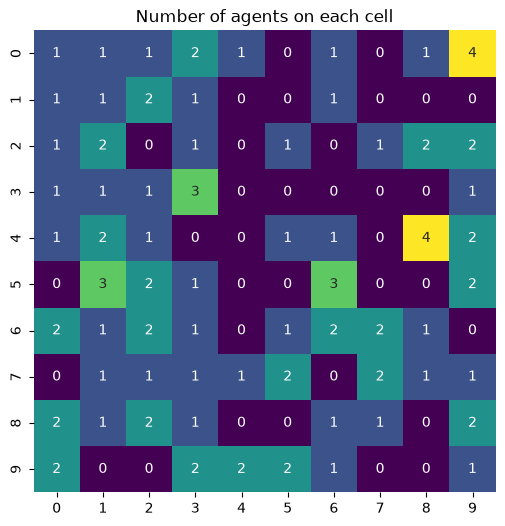

In [102]:
# 1
agent_counts = np.zeros(
    (space_model.grid.width, space_model.grid.height)
)

# 2
for cell in space_model.grid.all_cells:
    agent_counts[cell.coordinate] = len(cell.agents)

# 3
g = sns.heatmap(
    agent_counts,
    cmap="viridis",
    annot=True,
    cbar=False,
    square=True
)

g.figure.set_size_inches(6, 6)
g.set(title="Number of agents on each cell")

# Collecting Data
DataCollector es una clase de Mesa que permite recopilar información durante la ejecución de un modelo.

Podemos recopilar tres tipos principales de información:
- Model-level data: información general del modelo, como el promedio de riqueza de todos los agentes.
- Agent-level data: información individual de cada agente, como cuánto dinero tiene.
- Tables: información adicional organizada en registros y columnas.

El coeficiente de Gini sirve para medir la desigualdad en la distribución del dinero.

Su valor se encuentra entre 0 y 1:
- 0 significa igualdad perfecta.
- 1 representa desigualdad máxima.

La siguiente función:
1. Obtiene la riqueza de todos los agentes.
2. Ordena los valores de menor a mayor.
3. Aplica la fórmula del coeficiente de Gini.
4. Devuelve un número que representa la desigualdad económica.

In [103]:
def compute_gini(model):
    agent_wealths = [
        agent.wealth for agent in model.agents
    ]

    x = sorted(agent_wealths)
    n = model.num_agents

    B = sum(
        xi * (n - i)
        for i, xi in enumerate(x)
    ) / (n * sum(x))

    return 1 + (1 / n) - 2 * B


class DataMoneyModel(mesa.Model):

    def __init__(self, n, width, height, rng=None):
        super().__init__(rng=rng)

        self.num_agents = n

        self.grid = OrthogonalMooreGrid(
            (width, height),
            torus=True,
            random=self.random
        )

        # Create the DataCollector
        self.datacollector = mesa.DataCollector(
            model_reporters={
                "Gini": compute_gini
            },
            agent_reporters={
                "Wealth": "wealth"
            }
        )

        # Create agents
        SpaceMoneyAgent.create_agents(
            self,
            n,
            self.random.choices(
                self.grid.all_cells.cells,
                k=n
            )
        )

    def step(self):

        # Collect data
        self.datacollector.collect(self)

        # Move agents
        self.agents.shuffle_do("move")

        # Exchange money
        self.agents.do("give_money")

data_model = DataMoneyModel(
    n=100,
    width=10,
    height=10,
    rng=42
)

data_model.run_for(100)



DataCollector permite convertir la información recopilada en DataFrames de Pandas.

La gráfica que se generará a partir del siguiente código, permitirá observar cómo evoluciona la distribución de riqueza conforme interactúan los agentes.

Text(0, 0.5, 'Gini coefficient')

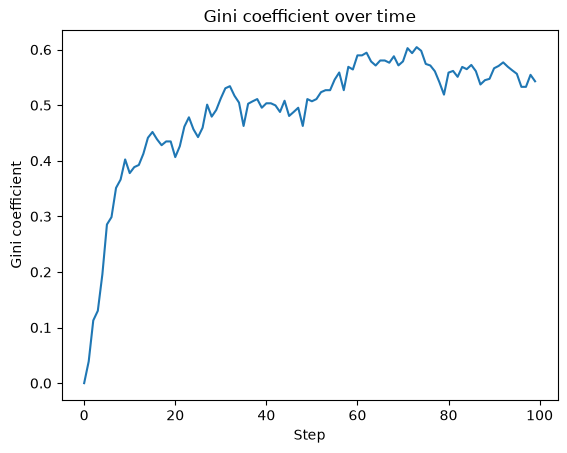

In [104]:
import matplotlib.pyplot as plt

model_data = (
    data_model.datacollector
    .get_model_vars_dataframe()
)

model_data.head()

agent_data = (
    data_model.datacollector
    .get_agent_vars_dataframe()
)

agent_data.head(10)

sns.lineplot(
    data=model_data,
    x=model_data.index,
    y="Gini"
)

plt.title("Gini coefficient over time")
plt.xlabel("Step")
plt.ylabel("Gini coefficient")



# Basic Visualization

In [105]:
import mesa
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from mesa.discrete_space import CellAgent, OrthogonalMooreGrid

from mesa.visualization import (
    SolaraViz,
    SpaceRenderer,
    make_plot_component
)

from mesa.visualization.components import AgentPortrayalStyle


### AgentPortrayalStyle
agent_portrayal() es una función que recibe un agente y devuelve sus características visuales.

Por ejemplo, en el siguiente bloque de código:
- color: los agentes aparecerán de color naranja.
- size: determina el tamaño de los agentes en la visualización.

In [106]:
def agent_portrayal(agent):
    return AgentPortrayalStyle(
        color="tab:orange",
        size=50
    )

Primero creamos una instancia a partir del modelo SpaceMoneyModel

In [107]:
money_model = SpaceMoneyModel(
    n=50,
    width=10,
    height=10,
    rng=42
)


Luego creamos el SpaceRenderer. Es el componente encargado de dibujar el espacio, las celdas y los agentes.

In [108]:
renderer = (
    SpaceRenderer(
        model=money_model,
        backend="matplotlib"
    )
    .setup_agents(agent_portrayal)
    .render()
)

Después configuramos los parámetros del modelo. 

Una característica interesante de SolaraViz es que podemos modificar ciertos parámetros mediante controles interactivos. El siguiente código genera un control deslizante que permite seleccionar entre 10 y 100 agentes.

In [109]:
model_params = {
    "n": {
        "type": "SliderInt",
        "value": 50,
        "label": "Number of agents:",
        "min": 10,
        "max": 100,
        "step": 1,
    },
    "width": 10,
    "height": 10,
}


También podemos mostrar gráficas que se actualicen conforme avanza la simulación.

En nuestro caso utilizaremos el coeficiente de Gini que calculamos anteriormente.

In [110]:
GiniPlot = make_plot_component(
    "Gini",
    page=1
)


Ahora vamos a unir todos los componentes para generar el dashboard con SolaraViz.

In [111]:
money_model = DataMoneyModel(
    n=50,
    width=10,
    height=10,
    rng=42
)

renderer = (
    SpaceRenderer(
        model=money_model,
        backend="matplotlib"
    )
    .setup_agents(agent_portrayal)
    .render()
)

GiniPlot = make_plot_component("Gini", page=1)

page = SolaraViz(
    money_model,
    renderer,
    components=[GiniPlot],
    model_params=model_params,
    name="Boltzmann Wealth Model"
)

page


Cannot show ipywidgets in text